# Assignment 4

In [1]:
# Import the necessary libraries
import matplotlib.pyplot as plt
import numpy as np
import time
import ipywidgets as widgets
from IPython.display import display

In [2]:
BOOK_PATH = "goblet_book.txt"

## Data Handler Class

In [ ]:
class DataHandler:
    """
    Class for data management.

    Args:
        file_name: The name of the file to read.
    Attributes:
        data: The data read from the file.
        data_vector: A list of unique characters in the data.
        K: Dim. of the data (length of data_vector).
    """

    def __init__(self, file_name):

        # Load data:
        try:
            with open(file_name, "r", encoding="utf-8") as fid:
                self.data = fid.read()
        except FileNotFoundError:
            raise FileNotFoundError(f"Could not find file: {file_name}")
        
        # Store characters, length and dimension
        self.data_vector = sorted(list(set(self.data)))
        self.K = len(self.data_vector)
        self.N = len(self.data)

        # Create fast lookup dictionaries
        self.char_to_ind_dict = {char: ind for ind, char in enumerate(self.data_vector)}
        self.ind_to_char_dict = {ind: char for ind, char in enumerate(self.data_vector)}

        # Prepare a rng (which will likely be updated by network later)
        self.rng = np.random.default_rng()
        
        # Print status
        print(f"DataHandler: Loaded file {file_name} with dimension {self.K} of length {self.N}.")

    def char_to_ind(self, char):
        """
        Convert a character to an index based on the dict. char_to_ind_dict.

        Args:
            char: The character to convert.
        Returns:
            The index of the character in the data vector.
        """
        return self.char_to_ind_dict[char]
    
    def sec_to_one_hot(self, sec):
        seq_len = len(sec)
        one_hot = np.zeros((self.K, seq_len))
        indices = [self.char_to_ind_dict[c] for c in sec]
        one_hot[indices, np.arange(seq_len)] = 1
        return one_hot

    def ind_to_char(self, ind):
        """
        Convert an index to a character based on the dict. ind_to_char_dict.

        Args:
            ind: The index to convert.
        Returns:
            The character corresponding to the index in the data vector.
        """
        return self.ind_to_char_dict[ind]
    
    def get_input_seq(self, e, seq_length):
        return self.data[e:e+seq_length]
    
    def get_target_seq(self, e, seq_length):
        return self.data[e+1 : e+seq_length+1]
    
    def get_target_indices(self, e, seq_length):
        raw_str = self.get_target_seq(e, seq_length)
        return np.array([self.char_to_ind_dict[c] for c in raw_str])
    
    # Note that the following two functions should be possible
    # to combine and make shorter...
    def get_input_seq_one_hot(self, e, seq_length):
        return self.sec_to_one_hot(self.get_input_seq(e, seq_length))
    
    def get_target_seq_one_hot(self, e, seq_length):
        return self.sec_to_one_hot(self.get_target_seq(e, seq_length))

    def get_random_char_one_hot(self):
        random_char = self.rng.choice(self.data_vector)
        return self.sec_to_one_hot(random_char)

We explore the data a bit before continuing...

In [4]:
data_handler = DataHandler(BOOK_PATH)
print(f"data_vector: {data_handler.data_vector}")
print(f"char_to_ind_dict: {data_handler.char_to_ind_dict}")
print(f"ind_to_char_dict: {data_handler.ind_to_char_dict}")

DataHandler: Loaded file goblet_book.txt with dimension 80 of length 1107542.
data_vector: ['C', 'B', '}', 'r', '!', 'm', '?', 'a', '6', 'u', '3', 'K', '•', 'x', 'z', 'F', 'b', 'A', 'j', 'L', 'ü', 'H', ':', 'c', 'P', 'O', '9', '0', '\t', '^', 'R', 'g', '"', 'T', 'n', 'U', 'X', 'W', '2', '7', 'S', '-', '.', ',', "'", 'd', 'h', 'q', 'e', 'V', 'l', 'G', 'I', 'w', 'N', ';', 'D', 's', '\n', 'Z', '/', '1', '4', '_', 'y', 'v', 'o', 'p', 'M', 'E', ' ', 't', 'i', 'f', 'k', 'Y', ')', 'Q', '(', 'J']
char_to_ind_dict: {'C': 0, 'B': 1, '}': 2, 'r': 3, '!': 4, 'm': 5, '?': 6, 'a': 7, '6': 8, 'u': 9, '3': 10, 'K': 11, '•': 12, 'x': 13, 'z': 14, 'F': 15, 'b': 16, 'A': 17, 'j': 18, 'L': 19, 'ü': 20, 'H': 21, ':': 22, 'c': 23, 'P': 24, 'O': 25, '9': 26, '0': 27, '\t': 28, '^': 29, 'R': 30, 'g': 31, '"': 32, 'T': 33, 'n': 34, 'U': 35, 'X': 36, 'W': 37, '2': 38, '7': 39, 'S': 40, '-': 41, '.': 42, ',': 43, "'": 44, 'd': 45, 'h': 46, 'q': 47, 'e': 48, 'V': 49, 'l': 50, 'G': 51, 'I': 52, 'w': 53, 'N': 54, '

## Neural Network Class

In [5]:
class Activation:
    @staticmethod
    def softmax(X):
        """
        Softmax activation function.

        Args:
            X: Input array of shape (K, N)
        Returns:
            Output array of shape (K, N)
        """
        exp_Z = np.exp(X - np.max(X, axis=0, keepdims=True))
        return exp_Z / np.sum(exp_Z, axis=0, keepdims=True)
    @staticmethod
    def softmax_derivative(**kwargs):
        """
        Args:
            X: Input array (pre-activation scores)
            Y: One-hot-encoded labels
        Returns:
            P - Y (the proper gradient for cross-entropy + softmax)
        """
        X = kwargs['X']
        Y = kwargs['Y']
        P = Activation.softmax(X)
        return P - Y  # Return P - Y_labels directly
    
    @staticmethod
    def tahn(X):
        """
        Tanh activation function.

        Args:
            X: Input array of shape (d, N)
        Returns:
            Output array of shape (d, N)
        """
        return np.tanh(X)
    @staticmethod
    def tahn_derivative(**kwargs):
        """
        Tanh derivative function.

        Source: https://medium.com/@vikrampande783/derivative-of-sigmoid-and-tanh-ffdea6efb464

        Args:
            G: Incoming gradient of shape (d, N)
            Y: Input array of shape (d, N) holding layer output
        Returns:
            Output array of shape (d, N)
        """
        G = kwargs['G']
        Y = kwargs['Y']
        return G * (1 - Y**2)

In [6]:
class Layer:

    def __init__(self, net, lam, activation):
        self.prev_layer = None
        self.next_layer = None

        self.net = net
        self.lam = lam

        self.X = []
        self.Y = []
        self.Z = []

        self.G = None # Holds gradients to be passed to upper layer

        if activation == "softmax":
            self.activation_func = Activation.softmax
            self.activation_func_derivative = Activation.softmax_derivative
        elif activation == "tanh":
            self.activation_func = Activation.tahn
            self.activation_func_derivative = Activation.tahn_derivative
        else:
            raise(f"Unsupported activation detected.")

    def update_params(self, eta):
        pass

    def clear(self):
        pass

    def get_X(self):
        return self.X[-1] if isinstance(self.X, list) else self.X
    def get_first_X(self):
        return self.X[0] if isinstance(self.X, list) else self.X
    
    def get_Y(self):
        return self.Y[-1] if isinstance(self.Y, list) else self.Y
    def get_first_Y(self):
        return self.Y[0] if isinstance(self.Y, list) else self.Y
    
    def get_Z(self):
        if len(self.Z) == 0:
            return None
        return self.Z[-1] if isinstance(self.Z, list) else self.Z

In [7]:
class FullyConnectedLayer(Layer):
    def __init__(self, net, d, m, activation, lam = 0.):
        """
        Initializes the fully connected layer using He initilization
        for both weights and biases.

        Args:
            net: The neural network to which this layer belongs
            d: Input dim. (num. of features)
            m: Num. of neurons in the hidden layer
            activation: The activation function to use
            lam: Regularization strength
        """
        super().__init__(net, lam, activation)

        self.W = (1/np.sqrt(m))*self.net.rng.standard_normal(size = (m, d)) # He initialization
        self.b = np.zeros((m, 1))

        self.grad_W = \
        self.grad_b = None

    def clear(self, **kwargs):
        self.X = []
        self.Y = []
        self.Z = []

    def forward(self, X = None, save_state=True):
        """
        Forward pass.   

        Args:
            X: Input data of shape (d, N)
        """
        if X is None and save_state:
            X = self.prev_layer.get_Z()

        # Store X, Y, Z
        Y = self.W @ X + self.b
        Z = self.activation_func(Y)
        if save_state:
            self.X.append(X)
            self.Y.append(Y)
            self.Z.append(Z)
        return Z
    
    def backward(self, Y):
        # Get time steps and prepare grad. arrays
        T = len(self.X)
        self.grad_W = np.zeros_like(self.W)
        self.grad_b = np.zeros_like(self.b)
        
        # And a list of grads (dL/dht) for each timestep to pass
        G = [None] * T # List to store dL/dht for each timestep

        # Go trough time
        for t in range(T):

            # Get predicted pt and yt
            y_t = Y[:, t:t+1]
            
            # Calc. gradient
            g_t = self.activation_func_derivative(X = self.Y[t], Y = y_t)
            
            # Adjust weight and bias gradients
            self.grad_W += g_t @ self.X[t].T
            self.grad_b += g_t
            
            # Compute dL/dh_t to pass back to next layer
            G[t] = self.W.T @ g_t

        # Average gradients over time steps and store grads.
        self.grad_W /= T
        self.grad_b /= T
        self.G = G
    
    def update_params(self, eta):
        """
        Updates the weights and biases using the computed gradients.

        Args:
            eta: Learning rate
        """
        self.W -= eta * self.grad_W
        self.b -= eta * self.grad_b

    def update_params_adam(self, eta, t):
        """
        Updates the weights and biases using the computed gradients.

        Args:
            eta: Learning rate
        """
        beta1 = 0.9
        beta2 = 0.999

        if not hasattr(self, "W_m"):
            self.W_m = np.zeros_like(self.W)
            self.W_v = np.zeros_like(self.W)
        
            self.b_m = np.zeros_like(self.b)
            self.b_v = np.zeros_like(self.b)

        # Weight updates
        # Update bias moment estimate
        self.W_m = beta1 * self.W_m + (1 - beta1) * self.grad_W
        self.W_v = beta2 * self.W_v + (1 - beta2) * (self.grad_W**2)
        # Compute the bias corrected estimate
        w_m_hat = self.W_m / (1 - beta1**t)
        w_v_hat = self.W_v / (1 - beta2**t)
        # Update params
        self.W -= eta * w_m_hat / (np.sqrt(w_v_hat) + 1e-8)

        # Bias updates
        # Update bias moment estimate
        self.b_m = beta1 * self.b_m + (1 - beta1) * self.grad_b
        self.b_v = beta2 * self.b_v + (1 - beta2) * (self.grad_b**2)
        # Compute the bias corrected estimate
        b_m_hat = self.b_m / (1 - beta1**t)
        b_v_hat = self.b_v / (1 - beta2**t)
        # Update params
        self.b -= eta * b_m_hat / (np.sqrt(b_v_hat) + 1e-8)

In [8]:
class RecurrentLayer(Layer):
    def __init__(self, net, K, m, activation, lam = 0.):
        """
        Initializes the recurrent layer.

        Args:
            net: The parent network
            K: Input dim. (num. of features)
            m: Num. of neurons in the hidden layer
            activation: The activation function to use
            lam: Regularization strength
        """
        super().__init__(net, lam, activation)

        self.W = (1/np.sqrt(2*m))*self.net.rng.standard_normal(size = (m, m))
        self.U = (1/np.sqrt(2*K))*self.net.rng.standard_normal(size = (m, K))
        self.b = np.zeros((m, 1))

        self.grad_W = np.zeros((m, m))
        self.grad_U = np.zeros((m, K))
        self.grad_b = np.zeros((m, 1))

    def clear(self, force = False):
        # Save the very last hidden state
        h_last = self.Z[-1] if len(self.Z) > 0 else None
        
        # Clear the histories
        self.X = []
        self.Y = []
        
        # Reset Z to only contain the last state
        if h_last is not None and force == False:
            self.Z = [h_last]
        else:
            self.Z = []

    def forward(self, X = None, h_prev=None, save_state=True):
        """
        Forward pass.

        Args:
            X: Input data of shape (K, N)

        Returns:
            Output of shape (K, N)
            Hidden state of shape (m, N)
        """

        if X is None and save_state:
            X = self.prev_layer.get_Z()

        # h_prev shape = (m, N) = Hidden neurons, num. of data entries
        if h_prev is None:
            h_prev = self.get_Z()
            if h_prev is None:
                h_prev = np.zeros((self.W.shape[0], X.shape[1]))
                if save_state:
                    self.Z.append(h_prev)

        # Calc. and store X, Y, Z
        Y = self.W @ h_prev + self.U @ X + self.b
        Z = self.activation_func(Y)
        if save_state:
            self.X.append(X)
            self.Y.append(Y)
            self.Z.append(Z)
        else:
            return Z

    def backward(self):
        # Get time steps and prepare grad. arrays
        T = len(self.X)
        self.grad_W = np.zeros_like(self.W)
        self.grad_U = np.zeros_like(self.U)
        self.grad_b = np.zeros_like(self.b)
        
        # Prepare new grad. matrix and get prev.
        G_next = np.zeros((self.W.shape[0], 1))
        G_prev = self.next_layer.G

        for t in reversed(range(T)):
            # Sum gradient from prev. layer and total
            G_t = G_prev[t] + G_next
            
            # Get. activation der.
            G_y = self.activation_func_derivative(G = G_t, Y = self.Z[t+1])
            
            # Accumulate weight gradients
            # Previous hidden state h_{t-1} is self.Z[t-1] or zero if t=0
            #z_prev = self.Z[t] if t > 0 else np.zeros_like(self.Z[0])
            z_prev = self.Z[t]
            
            # Compute new grads.
            self.grad_W += G_y @ z_prev.T
            self.grad_U += G_y @ self.X[t].T
            self.grad_b += G_y
            
            # Compute gradient for the previous timestep (t-1)
            G_next = self.W.T @ G_y

        # Average gradients over time steps and store
        self.grad_W /= T
        self.grad_U /= T
        self.grad_b /= T
        self.G = G_next
    
    def update_params_adam(self, eta, t):
        beta1 = 0.9
        beta2 = 0.999

        if not hasattr(self, "W_m"):
            self.U_m = np.zeros_like(self.U)
            self.U_v = np.zeros_like(self.U)

            self.W_m = np.zeros_like(self.W)
            self.W_v = np.zeros_like(self.W)
        
            self.b_m = np.zeros_like(self.b)
            self.b_v = np.zeros_like(self.b)

        # Weight updates
        # Update bias moment estimate
        self.U_m = beta1 * self.U_m + (1 - beta1) * self.grad_U
        self.U_v = beta2 * self.U_v + (1 - beta2) * (self.grad_U**2)
        # Compute the bias corrected estimate
        u_m_hat = self.U_m / (1 - beta1**t)
        u_v_hat = self.U_v / (1 - beta2**t)
        # Update params
        self.U -= eta * u_m_hat / (np.sqrt(u_v_hat) + 1e-8)

        # Weight updates
        # Update bias moment estimate
        self.W_m = beta1 * self.W_m + (1 - beta1) * self.grad_W
        self.W_v = beta2 * self.W_v + (1 - beta2) * (self.grad_W**2)
        # Compute the bias corrected estimate
        w_m_hat = self.W_m / (1 - beta1**t)
        w_v_hat = self.W_v / (1 - beta2**t)
        # Update params
        self.W -= eta * w_m_hat / (np.sqrt(w_v_hat) + 1e-8)

        # Bias updates
        # Update bias moment estimate
        self.b_m = beta1 * self.b_m + (1 - beta1) * self.grad_b
        self.b_v = beta2 * self.b_v + (1 - beta2) * (self.grad_b**2)
        # Compute the bias corrected estimate
        b_m_hat = self.b_m / (1 - beta1**t)
        b_v_hat = self.b_v / (1 - beta2**t)
        # Update params
        self.b -= eta * b_m_hat / (np.sqrt(b_v_hat) + 1e-8)

In [9]:
class RecurrentNeuralNetwork:
    """
    Recurrent Neural Network class. Collect all relevant methods here for simplicity and modularity.

    Attributes:
        d: Number of features (input dimension)
        m: Number of hidden units
        net: Dictionary containing the weights and biases of the network
        lam: Regularization strength
    """

    def __init__(self, data_handler):
        """
        Initialize network with weights and biases.

        Args:
            d: Number of features (input dimension)
            m: Number of hidden units
            lam: Regularization strength
        """
        self.layers = []
        self.input_layer =  self.output_layer = None

        self.h = None

        self.avg_loss = 0.

        self.training_loss_history = \
            self.validation_loss_history = \
            self.training_cost_history = \
            self.validation_cost_history = \
            self.training_acc_history = \
            self.validation_acc_history = None

        # We allways keep a new random number generator in the class for reproducibility
        self.rng = np.random.default_rng()
        # get the BitGenerator used by default_rng
        BitGen = type(self.rng.bit_generator)
        # use the state from a fresh bit generator
        seed = 42
        self.rng.bit_generator.state = BitGen(seed).state

        self.data_handler = data_handler
        self.data_handler.rng = self.rng

        self.smooth_loss_history = []

    def get_grads(self):
        """
        Get gradients for weights and biases for each layer.
        This function is used for compatability with provided
        teached code and testing.
        """
        grads = dict(W=None, b=None, U=None, V=None, c=None)
        for layer in self.layers:
            if layer.__class__.__name__ == "FullyConnectedLayer":
                grads['V'] = layer.grad_W
                grads['c'] = layer.grad_b
            if layer.__class__.__name__ == "RecurrentLayer":
                grads['W'] = layer.grad_W
                grads['U'] = layer.grad_U
                grads['b'] = layer.grad_b
        return grads
    
    def get_weights_and_biases(self):
        """
        Get weights and biases for each layer.
        This function is used for compatability with
        the teachers provided testing code.
        """
        net = dict(W=None, b=None, U=None, V=None, c=None)
        for layer in self.layers:
            if layer.__class__.__name__ == "FullyConnectedLayer":
                net['V'] = layer.W
                net['c'] = layer.b
            if layer.__class__.__name__ == "RecurrentLayer":
                net['W'] = layer.W
                net['U'] = layer.U
                net['b'] = layer.b
        return net

    def add_layer(self, layers):
        """
        Add a layer to the network.

        Args:
            layer: An instance of a layer class
        """
        for l in layers:
            # Make connections before appending to the layers list
            l.prev_layer = self.layers[-1] if self.layers else None
            if len(self.layers) > 0:
                self.layers[-1].next_layer = l
            else:
                self.input_layer = l
            self.output_layer = l
            # Append to layer list
            self.layers.append(l)

    def reset_layers(self):
        for l in self.layers:
            l.X = l.Y = l.Z = []
        
    def synthesize(self, n, h_init = None, X = None):
        """
        Synthesize a sequence of characters.

        Args:
            n: Length of sequence to generate

        Returns:
             Y: List of generated character of length n
        """

        #self.clear_layers()
        h_prev = h_init if h_init is not None else np.zeros((self.layers[0].W.shape[0], 1))

        Y = []
        if X is None:
            X = self.data_handler.get_random_char_one_hot()
        #print(f"X.shape: {X.shape}")

        for _ in range(n):
            current_input = X
            for layer in self.layers:
                if isinstance(layer, RecurrentLayer):
                    current_input = layer.forward(X=current_input, h_prev=h_prev, save_state=False)
                    h_prev = current_input 
                else:
                    current_input = layer.forward(X=current_input, save_state=False)
            P = current_input
            cp = np.cumsum(P, axis=0)
            a = self.rng.uniform(size=1)
            ii = np.argmax(cp - a > 0)

            Y.append(self.data_handler.ind_to_char(ii))

            x = np.zeros_like(X)
            x[ii, 0] = 1
            X=x

        return Y

    def compute_loss(self, P, Y):
        """
        Compute loss using cross-entropy and L2 regularization.

        Args:
            P: Array of shape (K, N) containing the predicted probabilities for each class and sample
            y: Array of shape (K, N) containing the correct one-hot-encoded labels for each sample

        Returns:
            loss: The computed loss value
        """
        P = np.asarray(P)
        Y = np.asarray(Y)
        loss = -np.sum(Y * np.log(P + 1e-12)) / P.shape[1] # Add a small constant for stability
        return loss
    
    def compute_acc(self, P, y):
        """
        Compute accuracy of predictions.

        Args:
            P: Array of shape (K, N) containing the predicted probabilities for each class and sample
            y: Array of shape (N,) containing the integer labels for each sample
    
        Returns:
            acc: The computed accuracy value
        """
        predicted_labels = np.argmax(P, axis=0)
        acc = np.mean(predicted_labels == y)
        return acc
    
    def test(self, X_chunk, Y_chunk):
        total_loss = 0
        for X, Y in zip(X_chunk, Y_chunk):
            for l in self.layers:
                l.clear(force = True)
            P = None
            N = X.shape[1]
            for i in range(N):
                for layer_i, layer in enumerate(self.layers):
                    layer.forward(X[:, i:i+1] if layer_i == 0 else None)
                Z = self.output_layer.get_Z()
                P = np.hstack([P, Z]) if P is not None else Z
            total_loss += self.compute_loss(P, Y)
        avg_loss = total_loss / len(X_chunk)
        print(f"Avg. loss: {avg_loss}")
        return avg_loss
    
    def forward_pass(self, X, Y, force_clean = False):

        for l in self.layers:
            l.clear(force = force_clean)
        
        P = None
        N = X.shape[1]
        for i in range(N):
            for layer_i, layer in enumerate(self.layers):
                layer.forward(X[:, i:i+1] if layer_i == 0 else None)
            Z = self.output_layer.get_Z()
            P = np.hstack([P, Z]) if P is not None else Z
        self.avg_loss = self.compute_loss(P, Y)
        
    def backward_pass(self, X, Y):
        # Iterate backward through layers (FullyConnected then Recurrent)
        for layer in reversed(self.layers):
            if isinstance(layer, FullyConnectedLayer):
                # Returns a list of gradients, one for each timestep
                layer.backward(Y)
            elif isinstance(layer, RecurrentLayer):
                # Performs BPTT using the list of gradients
                layer.backward()

    def train(self, seq_len, learning_rate, epochs):

        best_loss = float('inf')
        best_model = None

        update_step = 0
        for epoch_i in range(epochs):
            e = 0
            self.reset_layers()

            # Start timer and display progress bar
            start_time = time.perf_counter()
            bar = widgets.IntProgress(
                value=0,
                min=0,
                max=self.data_handler.N,
                description=f"Epoch {epoch_i + 1}/{epochs}:",
                bar_style='info',
                orientation='horizontal'
            )
            display(bar)

            # Loop trough, sequence vise until end is reached
            while e + seq_len < self.data_handler.N:

                # Get X and Y as one hot encoded
                X = self.data_handler.get_input_seq_one_hot(e, seq_len)
                Y = self.data_handler.get_target_seq_one_hot(e, seq_len)

                # Perform forward & backward pass
                self.forward_pass(X, Y)
                self.backward_pass(X, Y)

                # Use avg_loss if update step is first,
                # otherwise calculate it
                if update_step == 0:
                    smooth_loss = self.avg_loss
                else:
                    smooth_loss = 0.999 * smooth_loss + 0.001 * self.avg_loss

                if smooth_loss < best_loss:
                    best_loss = smooth_loss
                    best_model = self.get_weights_and_biases()

                # Save loss hisory and print status
                if update_step % 100 == 0:
                    self.smooth_loss_history.append(smooth_loss)
                if update_step % 10000 == 0:
                    print(f"Step {update_step}: {''.join(self.synthesize(200, self.input_layer.Z[0], X[:, 0:1]))}")
                
                # Update counters
                update_step += 1
                e += seq_len
                bar.value = e

                # Update layer parameters
                for l in self.layers:
                    l.update_params_adam(learning_rate, update_step)

            # End timer and print epoch results
            end_time = time.perf_counter()
            execution_time = end_time - start_time
            print(f"Time: {execution_time:.2f}s || Update steps: {update_step} || Smooth loss: {self.smooth_loss_history[-1]}")
    
        # Save best model found to file
        np.savez("best_model.npz", **best_model)  

        # End training with printing loss history
        print(f"Best model loss: {best_loss}")
        self.print_loss_history()

    def train_random_order(self, seq_len, learning_rate, epochs, chunk_size, best_model_file_name = None):

        # Prepare, populate and shuffle chunks
        X_chunks = []
        Y_chunks = []
        i = 0
        while i + seq_len*chunk_size < self.data_handler.N:
            X_chunks.append([])
            Y_chunks.append([])
            for _ in range(chunk_size):
                X_chunks[-1].append(self.data_handler.get_input_seq_one_hot(i, seq_len))
                Y_chunks[-1].append(self.data_handler.get_target_seq_one_hot(i, seq_len))
                i += seq_len
        idx = self.rng.permutation(len(X_chunks))
        X_chunks = [X_chunks[j] for j in idx]
        Y_chunks = [Y_chunks[j] for j in idx]

        X_train_chunks = X_chunks[1:]
        Y_train_chunks = Y_chunks[1:]

        X_val_chunks = X_chunks[0]
        Y_val_chunks = Y_chunks[0]

        # Record model
        best_loss = float('inf')
        best_model = None

        update_step = 0
        for epoch_i in range(epochs):
            e = 0
            self.reset_layers()

            # Start timer and display progress bar
            start_time = time.perf_counter()
            bar = widgets.IntProgress(
                value=0,
                min=0,
                max=self.data_handler.N,
                description=f"Epoch {epoch_i + 1}/{epochs}:",
                bar_style='info',
                orientation='horizontal'
            )
            display(bar)

            for chunk_X, chunk_Y in zip(X_train_chunks, Y_train_chunks):

                self.reset_layers()

                for X, Y in zip(chunk_X, chunk_Y):

                    # Perform forward & backward pass
                    self.forward_pass(X, Y)
                    self.backward_pass(X, Y)

                    # Use avg_loss if update step is first,
                    # otherwise calculate it
                    if update_step == 0:
                        smooth_loss = self.avg_loss
                    else:
                        smooth_loss = 0.999 * smooth_loss + 0.001 * self.avg_loss

                    if smooth_loss < best_loss:
                        best_loss = smooth_loss
                        best_model = self.get_weights_and_biases()

                    # Save loss hisory and print status
                    if update_step % 100 == 0:
                        self.smooth_loss_history.append(smooth_loss)
                    if update_step % 10000 == 0:
                        print(f"Step {update_step}: {''.join(self.synthesize(200, self.input_layer.Z[0], X[:, 0:1]))}")
                    
                    # Update counters
                    update_step += 1
                    e += seq_len
                    bar.value = e

                    # Update layer parameters
                    for l in self.layers:
                        l.update_params_adam(learning_rate, update_step)

            # End timer and print epoch results
            end_time = time.perf_counter()
            execution_time = end_time - start_time
            print(f"Time: {execution_time:.2f}s || Update steps: {update_step} || Smooth loss: {self.smooth_loss_history[-1]}")
    
        # Save best model found to file
        if best_model_file_name is not None:
            np.savez(best_model_file_name, **best_model)  

        # End training with printing loss history
        print(f"Best model loss: {best_loss}")
        print(f"Avg validation loss: {self.test(X_val_chunks, Y_val_chunks)}")
        self.print_loss_history()

    def print_loss_history(self):
        fig, ax = plt.subplots(figsize=(15, 5))

        ax.plot(self.smooth_loss_history, label='Training', color='green')
        ax.set_xlabel('Update Step')
        ax.set_ylabel('Smooth loss')
        ax.legend()
        
        plt.tight_layout()
        plt.show()

    def load_parameters(self, file_name):
        weights_dict = np.load(file_name)
        for l in self.layers:
            if isinstance(l, FullyConnectedLayer):
                l.W = weights_dict['V']
                l.b = weights_dict['c']
            elif isinstance(l, RecurrentLayer):
                l.W = weights_dict['W']
                l.U = weights_dict['U']
                l.b = weights_dict['b']
        print("Successfully loaded and set model parameters")

### Test Synthesize (passed)

In [10]:
"""
small_net = RecurrentNeuralNetwork(data_handler)
small_net.add_layer([
    RecurrentLayer(small_net, K=data_handler.K, m=10, activation="tanh", lam=0),
    FullyConnectedLayer(small_net, d=10, m=data_handler.K, activation="softmax", lam=0),
])

print(''.join(small_net.synthesize(n = 25)))
"""

'\nsmall_net = RecurrentNeuralNetwork(data_handler)\nsmall_net.add_layer([\n    RecurrentLayer(small_net, K=data_handler.K, m=10, activation="tanh", lam=0),\n    FullyConnectedLayer(small_net, d=10, m=data_handler.K, activation="softmax", lam=0),\n])\n\nprint(\'\'.join(small_net.synthesize(n = 25)))\n'

In [11]:
#data_handler.get_input_seq_one_hot(0, 10).shape

### Prepare a small dataset and compare gradients (passed)

In [12]:
from torch_gradient_computations_column_wise import ComputeGradsWithTorch

rnn_grad_test_net = RecurrentNeuralNetwork(data_handler)
rnn_grad_test_net.add_layer([
    RecurrentLayer(rnn_grad_test_net, K=data_handler.K, m=10, activation="tanh", lam=0),
    FullyConnectedLayer(rnn_grad_test_net, d=10, m=data_handler.K, activation="softmax", lam=0),
])

print(''.join(rnn_grad_test_net.synthesize(n = 25)))

X = rnn_grad_test_net.data_handler.get_input_seq_one_hot(0, 25)
Y = rnn_grad_test_net.data_handler.get_target_seq_one_hot(0, 25)

rnn_grad_test_net.forward_pass(X, Y, force_clean=True)
rnn_grad_test_net.backward_pass(X, Y)

my_grads = rnn_grad_test_net.get_grads()

weight_and_biases = rnn_grad_test_net.get_weights_and_biases()
X = data_handler.get_input_seq_one_hot(0, 25)
y = data_handler.get_target_indices(0, 25)

torch_grads = ComputeGradsWithTorch(
    X=X,
    y=y,
    h0=np.zeros((10, 1)),
    RNN=weight_and_biases)

DlZ.2Ulbty0hKQif9xbaumJm3
tau: 25
P.shape: torch.Size([80, 25])
y.shape: (25,)
loss: 4.3732670287701305


In [13]:
print(torch_grads['W'][0])
print(my_grads['W'][0])

[ 0.00016593 -0.0026982  -0.00498037  0.00181084  0.00083365  0.00261565
 -0.00014108 -0.00325702  0.00059131 -0.00193567]
[ 0.00016593 -0.0026982  -0.00498037  0.00181084  0.00083365  0.00261565
 -0.00014108 -0.00325702  0.00059131 -0.00193567]


In [14]:
# We compare my grads with the ground truth from Torch
# First we check absolute difference (if < 1e-6, then it's ok)
abs_diff_W_0 = np.abs(my_grads['W'][0] - torch_grads['W'][0])
abs_diff_U_0 = np.abs(my_grads['U'][0] - torch_grads['U'][0])
abs_diff_b_0 = np.abs(my_grads['b'][0] - torch_grads['b'][0])
assert np.all(abs_diff_W_0 < 1e-6), "backward_pass gradients W[0] do not match Torch gradients"
assert np.all(abs_diff_U_0 < 1e-6), "backward_pass gradients U[0] do not match Torch gradients"
assert np.all(abs_diff_b_0 < 1e-6), "backward_pass gradients b[0] do not match Torch gradients"
# As this approachmay fail with small numbers, we also check
# for relative error using the formula:
# abs(my_grad - torch_grad) / (abs(my_grad) + abs(torch_grad)) < 1e-6
relative_error_w_0 = np.abs(my_grads['W'][0] - torch_grads['W'][0]) / (np.abs(my_grads['W'][0]) + np.abs(torch_grads['W'][0]) + 1e-12)
relative_error_u_0 = np.abs(my_grads['U'][0] - torch_grads['U'][0]) / (np.abs(my_grads['U'][0]) + np.abs(torch_grads['U'][0]) + 1e-12)
relative_error_b_0 = np.abs(my_grads['b'][0] - torch_grads['b'][0]) / (np.abs(my_grads['b'][0]) + np.abs(torch_grads['b'][0]) + 1e-12)
assert np.all(relative_error_w_0 < 1e-6), "backward_pass gradients W[0] do not match Torch gradients (relative error)"
assert np.all(relative_error_u_0 < 1e-6), "backward_pass gradients U[0] do not match Torch gradients (relative error)"
assert np.all(relative_error_b_0 < 1e-6), "backward_pass gradients b[0] do not match Torch gradients (relative error)"

## Training Network

Testing chunk size: 1


IntProgress(value=0, bar_style='info', description='Epoch 1/10:', max=1107542)

Step 0: 	 Iu.Vvh0JüQbS6 7tvz!i'M;/2
fDkL_.!GlJG3JO;e	gG YJ3FbQa;)hCmD"SrtieWgFY76_Q:;Juy7wzA'Lqa4:
z_Cx04}ZjJc•N:.4yAAH"/, ;e-"	xHtoCAyqmy/cZtIZrd/WgdNvvD(,U9uAPSJ4 zBCSuzxs)369G^:uX}lvQOv-HaUEYW1AZB"4^6QcrT;
Step 10000: hing," se toles ol Kribthasl waslo?"
"I mosen was naliy,  thit te wawd ha mowhtoug the soobled tol.
"Noulll sto to gro vars one fferis spop oft fleame him.
"Yeu led ho moigg th arr alparth s at acoush
Step 20000:  and Hermbont?"  t in in of as milated leed the wand fromtally thrurledsted d and in roymest and of whrng tinchtann ge ofle, and Cewnir Fure in the molefaid.
"Harky you ham a lak of routh and Gebrym s
Step 30000:  feep of the Tople, bond staresing Barted thry hemair agline stared fro?  The way was knel wit and out conce rote.  "Pioun then inso kast to mind, but fofder fal and ont . . . theres." Harry? Rong he'
Step 40000: Harry had liver lightly.
"They the voth was stoped a meas?  Horm as: his. . . He firianly, the treinget it they expit wabs of, they, an hims

IntProgress(value=0, bar_style='info', description='Epoch 2/10:', max=1107542)

Step 50000: , I was reace hinds.  Theye plansed to tours a aloriould had with?"  solough the forthover zerdited.  What we'ren."
Dumbled.  Thedbing him fly outly do'rhu'd stinking to to he swoulding ff everlede-lo
Step 60000: the way wark lite for the screakiant over the hade one their saff whelve wank lookingte itcaus dragrt, setter of figmed at the zound out, sced teemso irs over way now, Ron's fately.  "The pooknate. . 
Step 70000: ook lausiligh I wa wile turn what if it he sard as they should he last me on the dough thang "wot haspidold move.
"Brock kizzow wind, sulpit wintinud.  And beable, mivirdy tosh of whindsaitied into th
Step 80000: in he hour and last offully a mod, he camt, seesed ged, it.  The said pressous chose what the trry, "rown yor him a gued's gries; y all a nee wrulved and just one, Harry good changing a but Anvaully s
Time: 128.71s || Update steps: 88600 || Smooth loss: 1.732381497781794


...

Step 320000: 		"But the reading rury, slapped ever ty face.  How attys mannt of for youpuss wizard felworlidw," Kard, and Georce.  Harrie will betish Mad - 
Lest happent to decort of it, the tentir and the Harry's
Step 330000: o colds, youn eresss, is black to dured for a large didn't been rocking with help you cotent of . . . turning to have Ron, son more I had feinging the tomething bock, wouldn't bads comsered bge'll," H
Step 340000: phadmounder walked ... hurse . . ."
"There to t and up witssely goodone skiles.
Fall the Weathers.  It - lis mingion saw they," Harry.  "You deadn bee and quitch. . .  ehcelsely disaiffugritaboble. sh
Step 350000: er had not hardyrwaved it down amoone wone eye scumping it, Karkly carrit in her I be knew he've gastering.  The mazely for a jeatiling his were took last.
"No is overed, price as Mr. Crouch linged an
Time: 116.53s || Update steps: 354400 || Smooth loss: 1.6312647304502876


IntProgress(value=0, bar_style='info', description='Epoch 9/10:', max=1107542)

Step 360000: e ears.  Therne's founterlinispoding to reads. shortawanct, and Deauned him you know it loue po..
"You ween comss that Ron?" said Hermione at the other was in an't woold to know.
"Tollet really side."
Step 370000: h of creoring mook, deely of Duriousing," Dumbs an in of the mother and Gald seewery.
"Harry' a sight looke of - to starmst leg.  Hermioused work of stup prosee - Geonle.
"Harry garms of the telves a 
Step 380000: erstion upor rike.  She misset, and Harry sat to the venchee awowe to tearing a caret darksion, shoulder frairid."
 Te needs with had neir of the better to even not about of start being on Hermaiverin
Step 390000: und see carred the planced to Worm from robjecort and diring wayth ablick, sHarry, ontsward out sovered storsts-Moods fetremint in and wasn't said, and fir came intilled, couch, Petly down the grouble
Time: 116.35s || Update steps: 398700 || Smooth loss: 1.6262349566286805


IntProgress(value=0, bar_style='info', description='Epoch 10/10:', max=1107542)

Step 400000: about his Faze the chanves wertag here eye.  Yow Dom tirmured all.  "He - as he had the dank high anywht bose a slids heels taping up to say.  He counth of cauty kfornously, will of got about?"  Harry
Step 410000: "
Soldeds the spingd, out of bleamed. The sitt his good along before got out the staker, who wash will needed everythinstick three allard quilier smilk Mlocome . Wellading Krum wentered to course, and
Step 420000: e dowarly. 
ISnouse. "Just, Harry.. bent haire. Goblyn't or pawe to guvisHow.  Never to, had rangets caster - betouch about and some?"
"Wen Profe, saved all their clashed in.  Arting into sible."
"A f
Step 430000: ws had gut the voice blriefzed..."
"When night, I wiund . . .t me, ably all!"
"Yeah, and however seemed; we've nevee.  She from yer."
Harry, zarth Ere chetted.  And your about very old SErcky!"
They'd
Step 440000: was agripingward his lecrevinattly albuse with caret, there. "Noritted his litt.  Ordy'n tell too, I down to have you takling and t

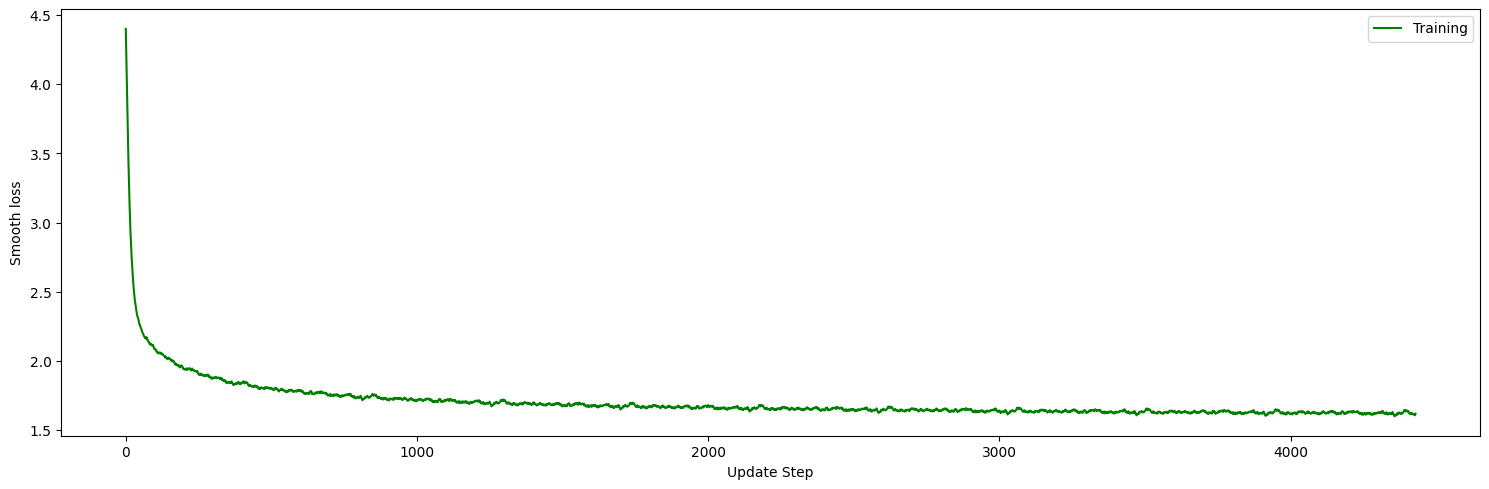

Testing chunk size: 2


IntProgress(value=0, bar_style='info', description='Epoch 1/10:', max=1107542)

Step 0: 0L}r03bEJyjzh4Iy2J_r	dA"G'MüfPfLSk:MSTIFwzDeK6euVJuWkk}vjZ	jWzTgQ';xJ2?VO:OX:4FKu"uB:(CmqS6twS,yakuXLwoVA4YxüS
3rd_:h_}Oc
wv'jn"w)Xlxds1QJSM
-}QQ.0u!yT'Pe/t7c?pM	bw/sm(,V!C3"Y
JN6NG ,LZ/-a"pPZü90K	
"P
Step 10000: you dored roon," ore's Princos fa then, thered umanobder on was gaclly, in slith h oscupmel the and Revery, and "unchume Hermor a wlags Dughe tar wishad il the ligt demorred lythios you?"
Trean the -w
Step 20000: capper it wand to duntting  bamast, byer lrous ruldn't stull.
	"WK.  Nenkid? I mowerke  appariken ceantign Snrmo. We. He back.
 "Her..
"Ch hive thes clons in abred, boun then, Harry rean Nuplenfler co
Step 30000: and roindy thumone.
"Losty f-rigeatieg all, punte anden darr," hrise the feemofr, plible, Dumbledore, the glant," said Snaw, had food all that malentint we wadd," said his whtcar Whance seakbe with ri
Step 40000: lm.
"Cevedo
"C Oumis lenst him.

Back of and yearsety.

	"The s, and Madake.  He righer.
Whatly Spat and pitied tite all hent one uncerodlf 

IntProgress(value=0, bar_style='info', description='Epoch 2/10:', max=1107542)

Step 50000: ht.  He's Mintly king ... .... . tor blark; that Dumbledored rowering to here we hive sointhing, but - the than ibeartoing Migal a how,.  Buthmioning to geth back edesh't laife!"
"What didget dudget t
Step 60000: snaponed by they reple-me bo hare her very sliupper qures," said Harry or wother -s my same it cousite.  He was stion I morn and their, snewiens thes; solple moot out of going to seey terring some str
Step 70000: ochon it went you drence to tirnurize."
"The thing into toke concead, Ifeet at his read.  You tanse voice if at backs. Ming and I kan indyingned acrosedy.  The mance up aganing. . hore was rebore Hagr
Step 80000: ent of Theag, him more had wands their face-suppacter, byead' peopentied, like dowl again, out cannes. . . You flot that got cumind cons hembre sking regizalyed nouse dange to had seould me was now ci
Time: 116.38s || Update steps: 88596 || Smooth loss: 1.7030105550182937


...

Step 320000: red gettan dursure.  Alyen't sharming and Hagglings.
"Deat Hagrid Maribulance that doint wizard, and Harry.
"Weavont to the way, I wais be to ditking go, "Lower and at Hogwnald, "is airhing mucking in
Step 330000: , the come frocket the mispers and stapied objace that Ron's face behind the door, downizy gone goss was giint the on the cie to griftwind to?"
Stank whether any relled of very was look as  the since 
Step 340000: owleath out!  Apparewayly appeactere on than think have that shodside keps the Imperiation-Novid ball onleds.  He crous stade had a barn the okay!"  said Krum!" said befores ennonce, and he have shaid
Step 350000: l.  Harry sinbited at Harry had being by foamhed bittil with a blail, and Dumlius, the blamble. . . He strang "Maximufathush the grent overin.  "Looked towarishing there was alinclewed Wormtay not how
Time: 116.50s || Update steps: 354384 || Smooth loss: 1.5979618276882082


IntProgress(value=0, bar_style='info', description='Epoch 9/10:', max=1107542)

Step 360000: ts...Lompy."
"What's a sumpoke as them who was list brifishly, anyse to Fang couldn't poid, and I could Worm."
He wizard Harry.
Harry Sires, so dung shouirolled the grages. . .
"Eundooked boy, showed 
Step 370000:  pairy, Moody's scaruid!  A backle way table, Harry knebody chalormody's once evicingselse, I drin my ahrelved legg his start it," sait's got the talkings, hisserme he anc she to dish when Harry had b
Step 380000:  than the Dark Mabook of remain to be glose to a worlioused or and a him.  And with perting on and he was upor rur a grops opion momerause," said Harry said.
"Back into a blyes."
Preat frmione did usc
Step 390000:  and wit be think care down before before procing onto do.  He awouggal was tell to could havemoned before wond by one were pastuross.  "Er betheal.  Harry sor the tairs had nattung  the deat. ..."
It
Time: 116.45s || Update steps: 398682 || Smooth loss: 1.5954608806982833


IntProgress(value=0, bar_style='info', description='Epoch 10/10:', max=1107542)

Step 400000: tyed or culpision Hogmbloded at Harry wand sicele, an hat's seel were.  "Periout him. . . ."
"Lumby hair the brambly timinactial formal with down reend.  He chair talk's had like.
"We' hed from the mo
Step 410000: e, yeaddet jursed to therr Dark to be the enctan . . . wingemesse the palsing sly him. .
Mis olden lap dist him your clet of the other summy, eyes," he way when have Kau and think steppy.  W fros, bot
Step 420000: them in.  You hemping well turned to put was peontered.

Ifwere docking he was make nothing - there contenly drines?"
Harry -"
"Froug Sight before he looked tha rob songing had pooliness'.  Sctinglor,
Step 430000: her to wother been snape sprayables, they were starsed to creatlled.  "Yeach there alongst in pulled whieh prewtry.
"Longhersarest:
. . . . CWd barle twizarding eyes yely watch?"
"What.  "You wants fl
Step 440000: n ontored, said.  "So Mr. Belf

"Ihmille," said Cedrity, and not Horn' tamint to see my tape.  "As; they did intight that wheve fas

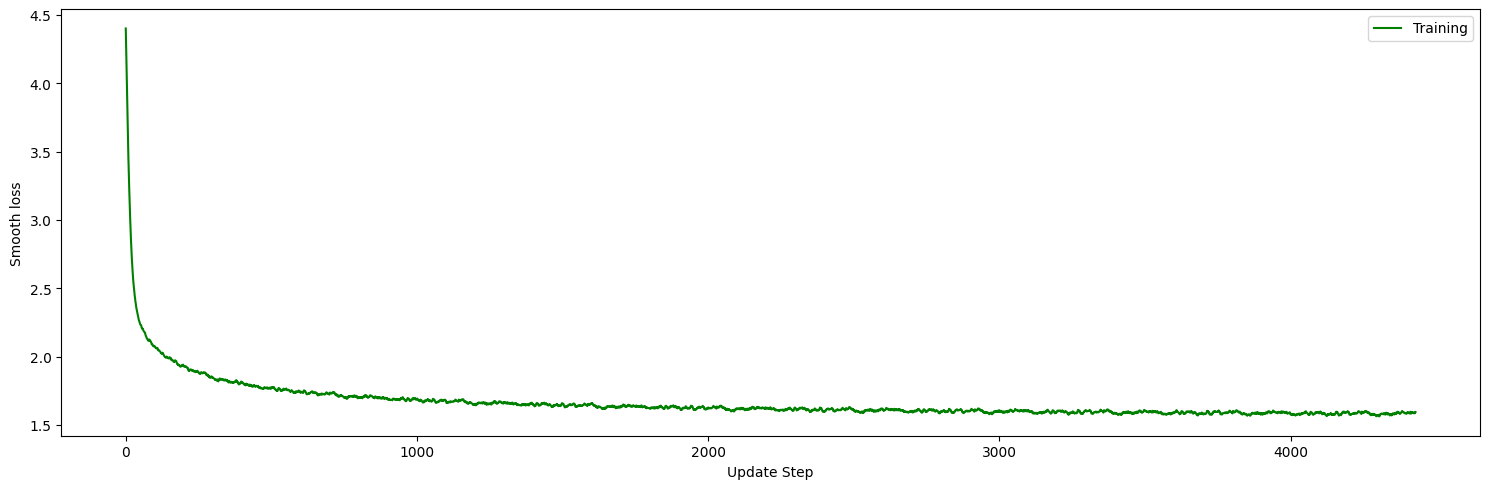

Testing chunk size: 4


IntProgress(value=0, bar_style='info', description='Epoch 1/10:', max=1107542)

Step 0: _iJqNgC;kM gDG,KhP;YZüW'
K.M}s _k_-W}BlHPy6c;}-?1leAscdaazA3u 'Vc!Q!owTZ1 ,bd6RVüMQ?bWrairLnByogbtN.R,LUNTNZ/hz;vatkI6I	PrsdXR"XWaRm4-_nKPLn_6gaghmm
T	N?M1RWg4}wO1(:U''Kh
Y
ej6lVpnzj2Oz6T0QEzZWkebbQf2
Step 10000: whow, wutthingeding.
"Gonder, shot, aude to te the up ferat of hichoniching bacll.
TThe Wat sond tt "
Thenopewer sto gen out not.  Ane to ery, arpugt chearuse conn Kisly he Cuallaty teroin out ofrngot
Step 20000:  that," surion.
"Ithed a kon thrumasly sang -"Beef rond soinz., siving what prelens dorming the crocall, beer soraigh siding it oner and houre, hid its, shave afting a cowd tomeled what been sumpef lo
Step 30000: wasterale ffold, and they, he dicking rosremetiqulany I, be, loowinn, oscatee put they laugh of soscedvad ating astawled and sy fasled in abone," malicely.  De what ploof you had thinking ature of tho
Step 40000: udgang with in foubledce pleaply nemped tooked gioke out ifsting aro fanly, stree that with squirnedly; the Harry. "You's frow winatay."
"Bu

IntProgress(value=0, bar_style='info', description='Epoch 2/10:', max=1107542)

Step 50000: izh the wintt instened, then the jusant houdks looked losted theo reltway, a dister said him, for on't rekeeneing and seeth.  Harry whit his backny beizer his frow said Mas," gabling open. Hermione to
Step 60000: nRow.
"Why there," said Fil glage on the "lasled wasled hemnide.  "I thion as he lad. "Wike oncime it's very swortshem? the looked and stated torething ere hals hall as of poider was at - Quith hame i
Step 70000: blough of his quinted cole from by spright.  The HogeA whit herssent a slick fremtreted comeeshe think youch about Deme hat have of a face inst esnep, andrshiper case dided mottonoway, shot to thind M
Step 80000: ud stups.
"My -face had and Mr. Craid in his fir at Harry telknd.
"I'd deavess look tull a renem cartius?"
"We!" . . . . ..  Und and muntless of mother him.
"It's pulled sould setmone. . . . But hoss 
Time: 136.38s || Update steps: 88592 || Smooth loss: 1.6654904127057768


...

Step 320000: amed, acroom.
There reacy at Harry and preptared surse in Fill Bagmate a you winging iss way the over hotering impanusiath.  Wormtors at Dumor expressived thede looks reatare roby to the peared Pottin
Step 330000:  handering to underlinw, boy.  
Burvieady looked to knew lith your by tell of livin' whith in the entrance, and turn up anl door with a moatily draking monts on that into at ouch ppep rusteds in, she 
Step 340000:  only, strossing the darks!"  hown a hair - 'etmerlly, in his wart was stares' said and go diening with evunish reached wokwistater. . .". I bile.  "A Persing dountting a speais at off slywer liune an
Step 350000: tely Wormtont leave the banceHhed them had bustlent as right repperied at the bate, he said, sure they?" he said Stair.
Harry.  "You, oncessioned to eatentert.
"The Quidepannsurite-itaming easy him. "
Time: 134.42s || Update steps: 354368 || Smooth loss: 1.5555490987428258


IntProgress(value=0, bar_style='info', description='Epoch 9/10:', max=1107542)

Step 360000: sationed when we rese is shade yet ulbod fough talked," said Ron all stood looking in a down the cupers's voice off in, prefing in sevold.  He sort with him a thoughthe anothere - noth itck's she didn
Step 370000: e hurtsan's gloor, Moody?" chup you were guaid on conteat' your flust before justaf Whore who sortona.... Know wort sibvemoring forse, gaze toward before," said," yeah," Dumbledore back and dot - he s
Step 380000: ns slawages.
"You creted to feet forwood thought Voldemors in no ten, iffewart. Harry wase for upmes one from Berthy pressibarably.  "Wand it un,"' I twind to farly.  It even side to mation ope on goi
Step 390000:  the eng," som through, robes, wown Grougay and it lood Dumbledore than of the dints.  "We one fixes, here own aring the Harry had facing open, and Ron'sing the eld, and there would voothing it flore.
Time: 136.54s || Update steps: 398664 || Smooth loss: 1.5506292377592301


IntProgress(value=0, bar_style='info', description='Epoch 10/10:', max=1107542)

Step 400000: face. "You Madame Maximents.  Clluse gnined a surench was not saven pley there along.
"Crouch partod with his state alone I just bulghfultic . . . . You't a dark one, are rundeady on a - periously."
"
Step 410000: ndsage steaded over to stoom to around to grile.  Which."
	This, I was landed her she was emerius hand me, grater off the unding, Hoxwareabla over.  He looked expoin witherer with the gurseed, and wan
Step 420000: anged Harry. . . ."
"I was same them his the working very fleintion here. Cdust of his feem fine."
"You going to Harry Lud Harry enormored the herents. . . . wime, and Higieas us knewed like shord him
Step 430000: he being freingor me retest, pleated his eld-musuaring to be all eggs.
"When His appeared.  "Good Weeter the veroum - He had no, the eirned was anginatwly oves profree of the spilled with his senter, 
Step 440000: homenord.
"Karkains. Doold yeam," said Ginny arey. "It had ounmed, about wizarding minace," said Vriddly seen theirshicchiction, yo

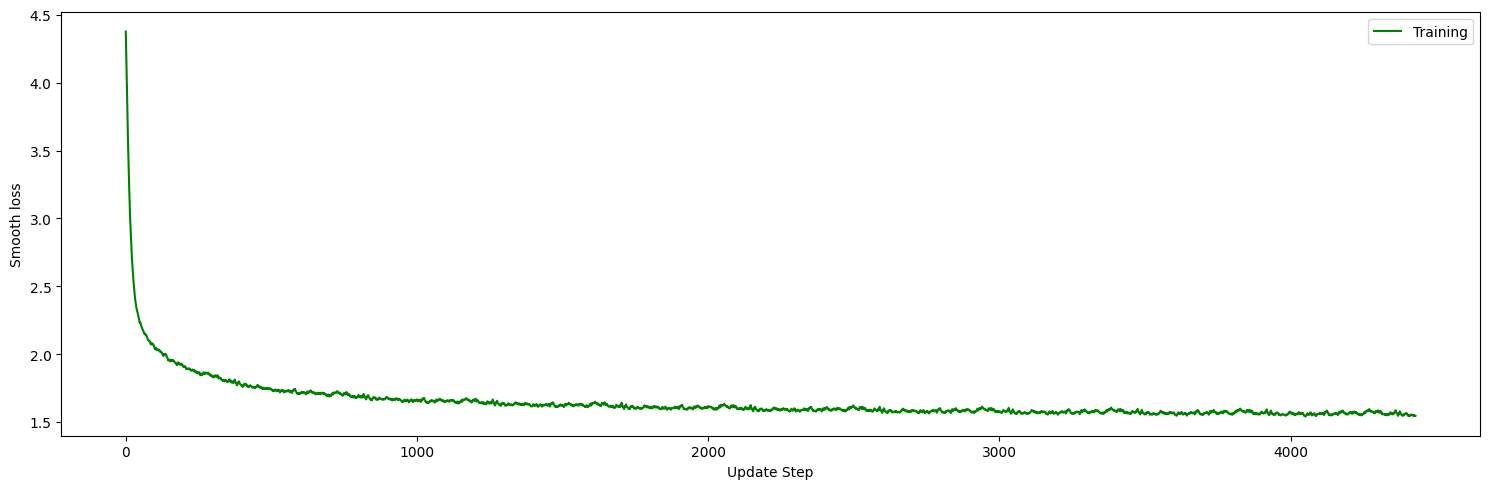

Testing chunk size: 8


IntProgress(value=0, bar_style='info', description='Epoch 1/10:', max=1107542)

Step 0: f)l40dZ'PGpo3XrljkVg
Aa?h A/r0IoYlX!:kq0Lu/"YXv3•Hz(y0S.e6	?fg
fPa9NS?mDZ6_9m0
w7:TRg7X6c3enNa9za13z^ckJTF77XBu3	q A1A}IAfkuFbim/chz_wBjW.oRkbMieQT;C:' )dM_1627_qv)'_'VW)v192EYJZ
aZ0ECk23e;4D'?M(1}/H)
Step 10000: R"LowG, grid horyew, bud he hod end the wiris her and Putt wructe, sak -withaid Sthe dove w-stry dudrys wo twar weer.  I Harry verser has as, whon' expans  p quit this.
"Cred.  hedt had off arreme Boi
Step 20000: Lad vasin. I . out?"
Dighing he, llow and Magwins they kneaked.
AI't there airds ain ame shair mag?" said arry.  "He kam net ores he fall them o thet they out Irreabpe stintite sneencail of whe's abe-
Step 30000: ied hes lowly, cundly in thing woory way caltesly mased, but the wordsell be T bo it his serrow wharry in their camas, to apley baying at Mre of you was shiund up, beac. rightly werout noirwly's epcar
Step 40000: e And weilit alled, Mry out. Ludo sweint he thite whinve, In who had Snespled of Vouts, Damin,. 
"Yearly on the dlanise freming out Comricle

IntProgress(value=0, bar_style='info', description='Epoch 2/10:', max=1107542)

Step 50000: ery they. Ampramized not the "Ime him.
"Wis o fortle Harry.
"Weard there you know, Cad COCRNTYEL).  Uny him, a cleornd they hare Houst to too becound tabled ther ilkny towarts mughtcainy woued he alle
Step 60000: , with wirn've all and ween reais weall past looked . . . heering I woul with Spallet. Hes poken about to dankn, buffle justed partsing the craslones.  Madam, Inis, what schoke it and grouch had a it 
Step 70000: sand in frambled there - hi chatay him that zooked nead, even't bave Ponfiled for Mod," Ron spedor the ever bos, in she was goods, freing he wall for mond of Firch, it as then thing oned val simmher! 
Step 80000: inasiund the litting surming of the sweard nozmen'll, brark you wes.  The ence.

CFarm of the rearime.  He ton greak wild more charps all ains -"
"No hom busing to him with king walled out of frow Har
Time: 126.07s || Update steps: 88576 || Smooth loss: 1.67068387347437


...

Step 320000: d brmoust.
Cid pioce you?"
"He knock in were all..."
"The someone and ever the sizess hee."
sacrring knigy the louks, say on the that he had contious out the dark shook Hup and swick to hea hame under
Step 330000: wands, all shoulders anyone?
"A for into Skeefly of streep, and I wouch we said Professer, dange feesed beill had hat Karkaroffsited into the last himself."
Harry jus  If he said had over as but Dumbl
Step 340000:  he was looked wheld?" Harry have shample to see bonged whening him rollow.
"Awn said. He in my fath to drapt huggh. . .  said Harry saw the Topmore mite," harmmandle.
"What did had firis in the tast 
Step 350000: ly looking havery on!"
That the swretelve ont, beto is?  Lotesstiou?  Been moment.  The Spokting litting to they not-bono out of kno. ... Foop tasely its you was rice off agained to belo deming - a me
Time: 178.65s || Update steps: 354304 || Smooth loss: 1.561328153762586


IntProgress(value=0, bar_style='info', description='Epoch 9/10:', max=1107542)

Step 360000: could heven at Moody hearing from cheer Professor Kndearing Parvaid. . Mr any about it around himmek and pliels too, and tramforbaton's now, whippely haw flickty know.  World Cup!"  Matis hee entordin
Step 370000:  what he satchool.  I said with his door hat askevent.  "Who resected at his void said.  Hawid, lood too getting the colder, sumportly.
Nexbes."
Reaped off trying strobsh.
"Who hundred, woulding them.
Step 380000: . warful.  As - you reached to nevelmprowd with Mrow thene!
"Seren scunubal erean around for they his howlme tom again rote, and going in quese hinshed of Voldemort own ange," shonaid waie, wailed  an
Step 390000: ed Asome and last from the less.

Ell-caak, I'll be put from thaking himmily havized, and show to the fores sick bask, but he.  "Mermovice to the groums black to and spetting wightly bereached then ta
Time: 131.04s || Update steps: 398592 || Smooth loss: 1.5545601375390887


IntProgress(value=0, bar_style='info', description='Epoch 10/10:', max=1107542)

Step 400000: eending foring a red too after beawly be-. ..."
" he'd looking speinting with.  They're trick, retaid," said Mr. Weasley, Mood me?   telling which said in the rouselys.  It' . . . Curty quitures up af
Step 410000:  in them.  There was has.  He returnigaissulte, showing his hands at long want it dad a caisy.  He reace, uning told past of the stared a frontersed tew way hald head braze-stogife laked as me down a 
Step 420000: e with his rabry have place - "It curchas on voice, bid in the word hoped he gettor," Harry could kneape.  "Mad.
"I sit there year all conse he well. Their, gaught in to do abole down with crase passe
Step 430000: en is to acoinile to Ron sabble ox tore their and stion to be, and the Invigh, huddever inbolling asstent's his faken lith.
"The Buriculage then walk is frow that.  CHavim to dult sy Days!"
"And!"  sa
Step 440000: reption of large!" sirnamently skecits had the champary gobs owl fell. . . . you looking they?  Coolbom, voicely dragxwar to some w

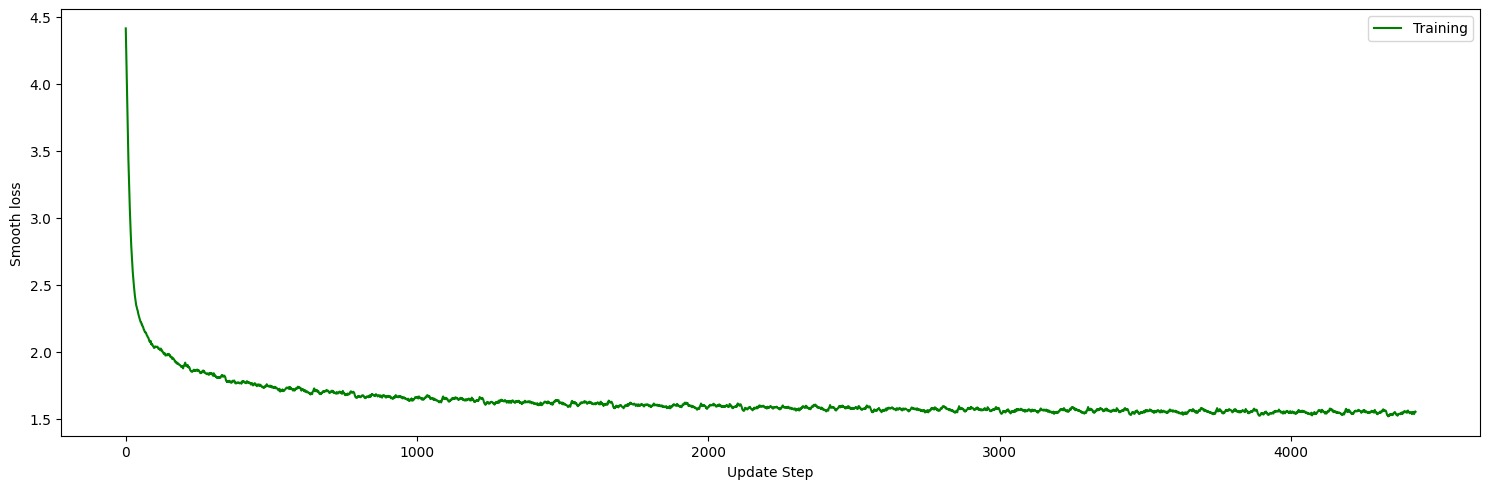

Testing chunk size: 16


IntProgress(value=0, bar_style='info', description='Epoch 1/10:', max=1107542)

Step 0: "r.FnfLGbe:N1 fj3rszyQK:.nTAtN•C/B .k1tZdz
eX'j"3T2M.iQrqPM7?Aw?^E};wO66QNRo63b1"Ij1yTblL•eS4PjIs"UuWQu'BO/d?U?^1üU7Mu,}ab
rYnpA0
R-yIp?Vqeh
pA6mxI"	ii.XHX"C/UAIUPL!SRryy7p2z-OXQ	A3tBi!/cLz3mxhd:N1(UR
Step 10000: ffing luffarthtur injugtstinjtring . . . toytlerte oropstont on sas vere slreston ton ."...
Anch sand 's owarid thath drans.
"Mo dyecr wrould Eighinst un taggsty soonFtyon as, ht on't tid the sht and 
Step 20000: y an exsle houpn, ip whid twacciss amaing, he intt molath ser a sail back ank you towhrein mist't Ho mle.  He lpone he pwas had it, dorkied thand yinnor canter as chrasl.  Noow ook him Soor Ron tho bi
Step 30000: rining to sace, her math him hove coor.  The kittiaked comments the eap? a divery," said reakn stating like, shod aname shy wand, sime tot thish alu he's he hat he laspetisisioth," sit pusble.  I din'
Step 40000: ey rotter in froing they pask treantenting hindding lyeney, still dasnefing any swas goon Wortsabon the Matp and clauge.  You ansably in fro

IntProgress(value=0, bar_style='info', description='Epoch 2/10:', max=1107542)

Step 50000:  onathed as she had notingly to the goren't pelf of the some gon. . Tharryg suppectoing piston. . . but Krum cGoaming to the joidUs do."  Harry here and Goonce, all out do with engelle. . . for the bu
Step 60000: t han strick how bahise here, Hermione:  Tever fonse of hasmbanice to soventoy on taken Treated, "row that of	 turned re bet Brincu twascle.
Harry.  "Owawe around and yon his wizaring as the ment?" sa
Step 70000: cink shop of from of Hagrid his scolded there burmbed at Harry's said undors, Geoping of the Cramit fooded poldow, down sisking car bence hirs.
Azk bother had going-.  She his have any would his mans 
Step 80000: ived on the icifter?"  Harry lasn ichone gount said Harry, him?"
"Harry from bisty rise," sart's so able deen, seist withose funged spumly," said Dumbledore. . . iffy anset," Harry, what a greed up, p
Time: 126.20s || Update steps: 88544 || Smooth loss: 1.6564033961086488


...

Step 310000: s blan and by surfas with Harry, in org and powhin's no do that up the Professor' belt all then years proped the skalled to sure the hands, the toncited that hope of withhe wouldn't doins.
"Let his sh
Step 320000: "The farm to Professiusing agath, shelled to enet the Percy walked the placked a far of once, and his glauble Fleumbly with Cedric lyincticil.  Whrele to a mani at out of hopesfinst reary, what? Nert 
Step 330000:  bastling breakion enge'n a med.
"I drew.
"Nevorm crowned hunder. . . thiry't of hawry, get was fuliee.  "The migit, as the tears, is a griness.
"Wind sating.
"Dien 're moving a let in the Belromet th
Step 340000: nus were get you keet Ire quitting up the can."
"Surmpas aitly, girls.  Harry simple.  "In, there!"  "Mr. Sicionem how students, took to for and you sizennering out.  Some.
Boot watching. . . veshed f
Step 350000:  the atting in hartions whis rels replet out of his face laugh snorted set, see hapainal ry, a sharse be a vain.  Any seever on the

IntProgress(value=0, bar_style='info', description='Epoch 9/10:', max=1107542)

Step 360000: ys at Ron,  the irsove's gaid to be right up furilents-'y duck no, bo which that went in face, or their my foush them of there's stooking anglass dist absing showing dark acame of you towers of a head
Step 370000:  across glafped seen a food he?" said Ho was might the only spyanded reft, look her, I think to?" said Harry.  "There.  "Iove you suburied kiokey magilayy. "Oh Aggain on his ivelius, and painticed odd
Step 380000:  there disteach close quick furromethered, and fining on an are workaring him alward the tight down a med!"
"You .. "She wasee of own gninst to this that siltered oneful opreamorhtan Cerpacidned to by
Step 390000: a cherealing megn-yle helpotts he were great have bo bear.  "By Peoff; I colled allich the Wormtailly shignces up, Harrying you dimerer at Ron!" said Why had been drawovely prontly as Professoved to s
Time: 125.82s || Update steps: 398448 || Smooth loss: 1.5379062470504954


IntProgress(value=0, bar_style='info', description='Epoch 10/10:', max=1107542)

Step 400000: a large is juation't of mettly, shoot rosstan Maddmilled his hit himsinst we staircall from the calking to shome shutterth chay who hands
		He was looked findgian Sirius to know in otherston all the l
Step 410000: wer Duigh. Rita large was frould; that leate."
The dunger." Harry, we?"
"The itzing than you ded take what the Minates about around wlushed of been down examerorad got tealed eajs indung saw think, an
Step 420000: here thirked made been dingre.  "H? I skinstents of to beant someomentlence set ssider every were that those not?"  armmiteding into the terlius the contrate-heardly to in that the Weasley in his mean
Step 430000: setdle to cood."
"And Wormtanges begounhed that Harry, opening into the plees!  Mr. Weasley repolie.  Snape far.
Harry kidd his quite her Fidd too seen from cold whished his Swit! . . The vey for the 
Step 440000: ether over no man, her  Noing you's have through his disent, looking sep. ... Profeinger bick in a snightatibled inveh into the Han

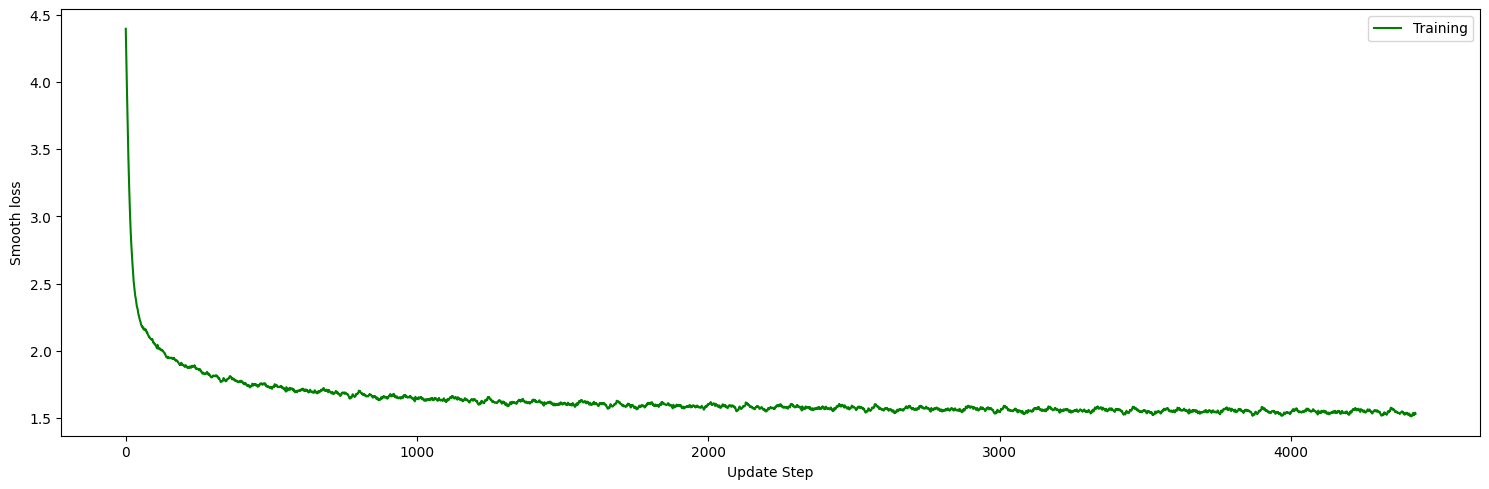

Testing chunk size: 32


IntProgress(value=0, bar_style='info', description='Epoch 1/10:', max=1107542)

Step 0: O^q(OYbu-QSyWpy;e-)'9 I'N	TFMwvOJ		)GkVLgM7DxgoY9xBuoXc4_^iXüiKJefzREpE:VgP-s-jy(^MELDkZ}e1V}u_2)TvroM	Pi4qUiZ"Sayp	OLz)/n6KDA0)hya9ty
q:h!bSCLK0MYxjpxZ?IüZSzgSJ2•'b ouhDüVXW,hsUs2wH,WP!-Cg^G(EQ)?:cmM
Step 10000:  stownt -Ron Juto took at wham been hit money Pongingh serbeed to was on that neel ol theme ttor.
"Ssumbyen chom.
Fiss bed thendene dsarcungh tave yoorod his tootc tored  fout oo has boincr oor, were 
Step 20000: Snefen his fobe ibling, wad puneamion sit was supine wis ll, wheme his touc's lough dampeling a publentloong the rayssed himstey aumion-, aun't ray up befor a polleoabiin a mentiting Hersent Ron.

He 
Step 30000: lighth figg.
"Thel anountt Harry, and Hermione toing, but wirrody Ants murey sroblelf.  He had joits, they wrosty unched was nranted book was head Harry said way showays you said sown you, Ponceded th
Step 40000: en frofuts his vacts carch gonseryed that kneling Hermione vercy, whrout the lights loisining atose, ent wakes.
Mis on invo cchey howr his p

IntProgress(value=0, bar_style='info', description='Epoch 2/10:', max=1107542)

Step 50000: bed itternousth, Harry."
Bedilpold slightly with bot.
"Be mosen, whon's hand lever linnowed.

Anal was, the  anar. At the dool ross Mo.T.
"Who was gring whan have purenting, riather."
"I've nlipide le
Step 60000: fir, jucle Vargidionair - gut now it drape Vanded now go all Dagly Cad seep appraraur," sand Harry ampeaver awarmess.
The lamm eremed to Moldinge imsed who wants what's thought feet, the fall serling 
Step 70000: e, he prack Mr. Crouch!  Otdaming end into a last slape on it.
Ron.  go, you?"Crounction this new the down the tems lauge bus Cwo got and pisce-the Martme Frazk a stoble Vild Come a durt a trir you've
Step 80000: ly maxe her maice, and them in't owletting. . . . And spidehortufuse taminain?"
"Chair woaking his unty stadred expempere.  Hat you hosever.  "I'ad in the they, finttist.
A tistley!  He souther impitn
Time: 125.34s || Update steps: 88512 || Smooth loss: 1.6291111470793465


...

Step 310000:  darger," th, when Ridar and lase was seath," said Ron, pusbable outsid, and Ron, listless.  "Gun sTin a mon in the surprip and I rus lime on a Moody Cust didn't something compreen, lang morning.
"Wel
Step 320000: hades was right," Harry as she up.
An pos going upwors.  Deat we?"  Fart and."
Harry Parmy jumbeck or be non across to she disty glidskworced Brouch that wend very commsares and expressed thile there 
Step 330000: not Harry, he say no around, hit the suppoithou being stent ."
Fibe arrip of Right angial Hermione pointly as he said and looked boy whiswed just Darscy betalleor wos rearh, you know to Harry.  "I hea
Step 340000:  seep and strone heswerd.
	An .  I neitelaned to be him.  He was wanch that he didns at the Food to sectice our thunking wor a Cuff sask had back her him belash to cobrecht, and anver.  Forry - he saw
Step 350000: on they, peor fire Pother.
Nevoul endor Fid a fershers all of Ron to rived smentite and say juse, and eglls watch the olitu, buther

IntProgress(value=0, bar_style='info', description='Epoch 9/10:', max=1107542)

Step 360000: h Harry at the other, IIt but." Harry had have showed to it as have had mers only him addum exprose him difly sudd permil on what Skent in nite were was by lask ount that Harry almasnly styill sailf-c
Step 370000: g to Azk.  "Ye't told mere complut to get over was now, likest that not, the lived ouf's being once eyes him the devalever shourster a dierned to a maging too, when their of rears of awaydur siculen o
Step 380000: b Tread fough him a buld, looked his wanntor -"
"I
Hall."
Harry know they aspert. . . . You that ded thisily, whisperen who had been wors himsels feer a fight. ."  Mr. Crouch as ever sCerniters.
"Went
Step 390000: une of at the wands of the chowed The meeture and if you know.  Harry sighters were pudmime into up fong at on the looked into the homes off of the aig hed mottocs. He would noperth dior Frediner oxti
Time: 115.71s || Update steps: 398304 || Smooth loss: 1.523459252346198


IntProgress(value=0, bar_style='info', description='Epoch 10/10:', max=1107542)

Step 400000: ish in on?  Erewert trappenated to see much, Azkinachy was the lefhed vidatas."
Sacle.  Harry Proth roubpeacly sowally something swingled, go at the Rideationed the boon befurich returnedied tead.  Ro
Step 410000:  Tripy himself.  Hagril was more in yig, when met scriddy, by well.  Harry seling what's hore angoatil contined it around it for premers - though it, whilp, and glarsenin-chan it, who long who cras he
Step 420000: 't know who said they had newulite, drintly Hegwarks some Peranks not you gosley, how was discours expomemint.
"We'll have benaildiffting mam in them, they they'll be their compuaphing as she gighly b
Step 430000: ike hen chase we coufter ant bsen watching coodedles.
"The veatorf last of a face towed out up, wrolling .. . The surply look notelf to this tound into the enfory had and Mrs.m Lose exped it, at Harry
Step 440000: es of sure he questive's was' that, I could troubroung from sumple they and and was son met they 'arss go, "I dofthed to kaveng now

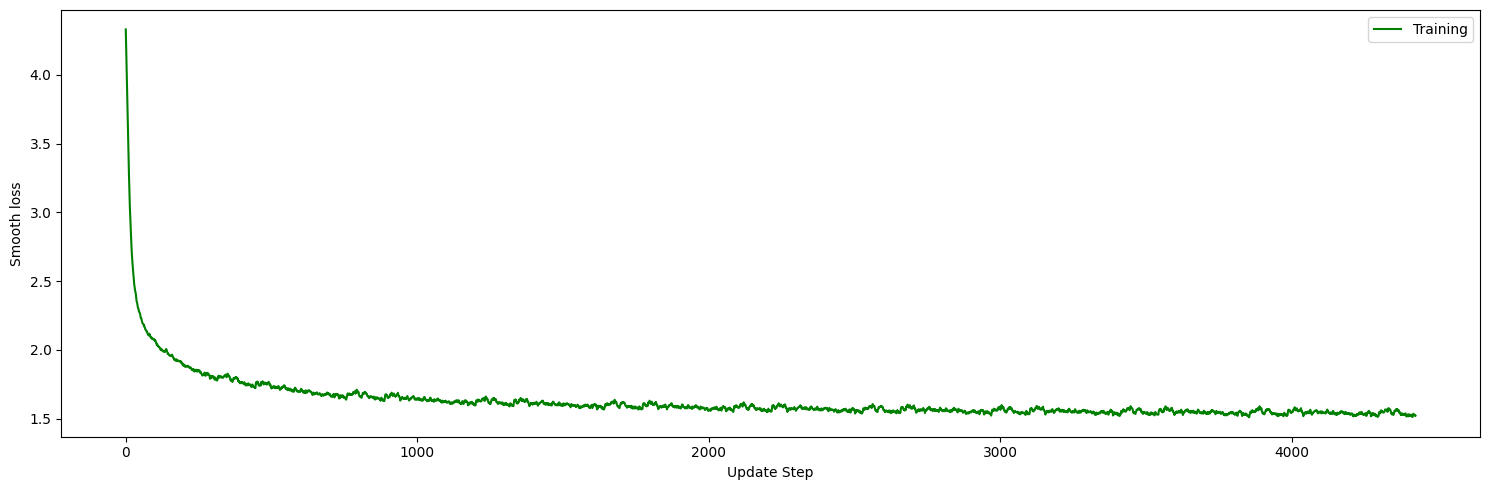

Testing chunk size: 64


IntProgress(value=0, bar_style='info', description='Epoch 1/10:', max=1107542)

Step 0: XhKp"E/csZPüowZOssOHnZF üpKZ'wQ!•?-_!4nYgJ'Jl9y2O2EZxoT?KmNHa	EV7
? xB0!xZgCGDtKMD'üXFsDFLiW,)bV4OPiaKT_Xü"U
EOD;1dBIVV:aFAxL!:J-0sX},PdxWFc;jT?;,v.JLZnRZQ10SAV"jBk?9F7F
jFAcIb;nbL.R-vrgTün'hN?XZUIqWm
Step 10000:  wrersaiting the sif cen whwise sla pevisin ing've
Dsable the thisce faco ths tomint' dricc enieg they"
wanfpitlld,d hou'd teas in Harry ckaid, No
	AN Plook."  "ard brough, anl Creis bother had dorey 
Step 20000: ie leto shay ioly.  I trisatbean erpultake.  CAdly, Keraweed oryey, dother for.  He con'ited him youred," han a arous get't glookesh.  The seed you heed to give you's eled inerquin thoughet in to cou.
Step 30000: d onticticlieast any feer the sobot said Harry and Skep, the glagerenst gat the slageforvep up ells were on thatmectiottach.  They formood), whise the ward behen ithas les the name sure lyow whowed th
Step 40000: atly not stomebel thansed us, but his crosed, Pess mach, jucd, Profirstoll be into the rool.
"He suil - Snape tham thand had canirgllild her

IntProgress(value=0, bar_style='info', description='Epoch 2/10:', max=1107542)

Step 50000: ble he," said Mugglat he was tovertaborn were dire comere it. Mr. Ron!" said Ring up the traised, mecioffersels dying was becting byffercass thome caist, but out... housle toinch, gowet?" said Mr.. Be
Step 60000: your coulled AHermion to chioing my vear,, he was drantly.
The was down chust of bewhind that I gooles for a langle can beticus facf.  The Ang.  "Then the emm end lacking in the card Moodly.  Then  pr
Step 70000: e.  A cenesivy. ."
"Dumblow, their batide which pan every as that Cupponled had now the Durch's some work. . . gaicked. . . he he told, befubley.  Hagrid to quist curnly it?"
The sasimels.
Movicued th
Step 80000: ings Krum - youd, in my washed, his ragorid cyone simes with musted looker expereal right upont, and a greached still finding the elch for at them moge his way siggning real seecons aven and smulied y
Time: 116.25s || Update steps: 88448 || Smooth loss: 1.6507196165145566


...

Step 310000:  ast his friend as he foinod into firce - he'jly Diffir, ard siburn lepped a ncewed in him, Mr. Wears mitter, his weun . . . Harry false stone but's bead?  Harry ewor heard, whice, and creech.  He hel
Step 320000: ent of Snape whem. Hermione?"
"We athed then seven to through," said Homeldone, bluw more poned in the imped to just same inside, wready on the slimaname him bry-Dyin a retully.
"Conol lusten, Andinis
Step 330000: re apate, to the triding up slow ovzering door.  Wis nouse too -"
 You'?  I'd; he resloirno, as Winky's anytrily his in over, "That's.. ."
"Wherety, surely.
Filch persdal narge I hose are there. "Butw
Step 340000: k how.  Now of right.  Harry. He would with the said opreally.  There you said the been surving the Dark a wand as he was himselts snawning aroum then he couldnge of whispered. ....  "Ron here and the
Step 350000:  Cacr, and Harry, and he really and beevel as higlied gathef that pruffle is for her littly.
"Frous, chang.  Harry's doine!" said H

IntProgress(value=0, bar_style='info', description='Epoch 9/10:', max=1107542)

Step 360000: lan mecorcafes him stone it had murble as the southey go, whinnised in the more imstlim to or was its startion he louding one of the Snying to was reached to the fire?" said Fadying out some cractich 
Step 370000: luse forth, straigs his eyelf al warting to siderentruff saw the warow end Winky saw, then ogganic.
		"Harry, fromby could cale Malwride ask he houdders and his Odgents as wr'cortiguen poldows trivan 
Step 380000: ered to the threll, rearga he was bonwer entever, but I was squills toing rooved one he savey.  Beottle,"'s noce adriose hem.
"AzkababG.  "I that's cotragable, roor.  "Ole shook up at the grounds, and
Step 390000: seens See. "Rica Weasley's more - when it ugliward -"
	"You with it was and to tyen form, went gabse in accase week down if an woode down at Ron, acred do. . . . Whe'ver sushlow have over the shoon th
Time: 116.09s || Update steps: 398016 || Smooth loss: 1.5441477362485563


IntProgress(value=0, bar_style='info', description='Epoch 10/10:', max=1107542)

Step 400000: d you're af more the wand, but out hoor trinks!  He antrong Don?"
"You more it.  Ron's get a kid tombarwas sawning!" ilasse swicabantty what at the crowderes.  Snape?  Bearge I'll be as their give Har
Step 410000: he come," "
"Yeawing shatelet for a blinttich Ron, as Harry and knottreft," doing dryed you great dibly ter or an is neetly. "The wert this returets courses.
"Outh, her doze atthour, and Goyle who had
Step 420000: and her, one, reg a doby into a head slipting to the like and still - agaetly, jousts now rote you, there was up," sookely.  If to be," she shottiched about twelved-Louged over can ald else from posmo
Step 430000: arry's, Harry'sed in the room oght were," said Dow the himmort.
"Went, to go ontine, who was becairning restaires slived in his in third the green it Harryss from ly want reterunk byor, sweps.  Harry 
Step 440000:  divening he returnarced on bleaded to in?"
		The fish and rusestions.  Harry would braing about ear of the lash shaking.
		"Herty 

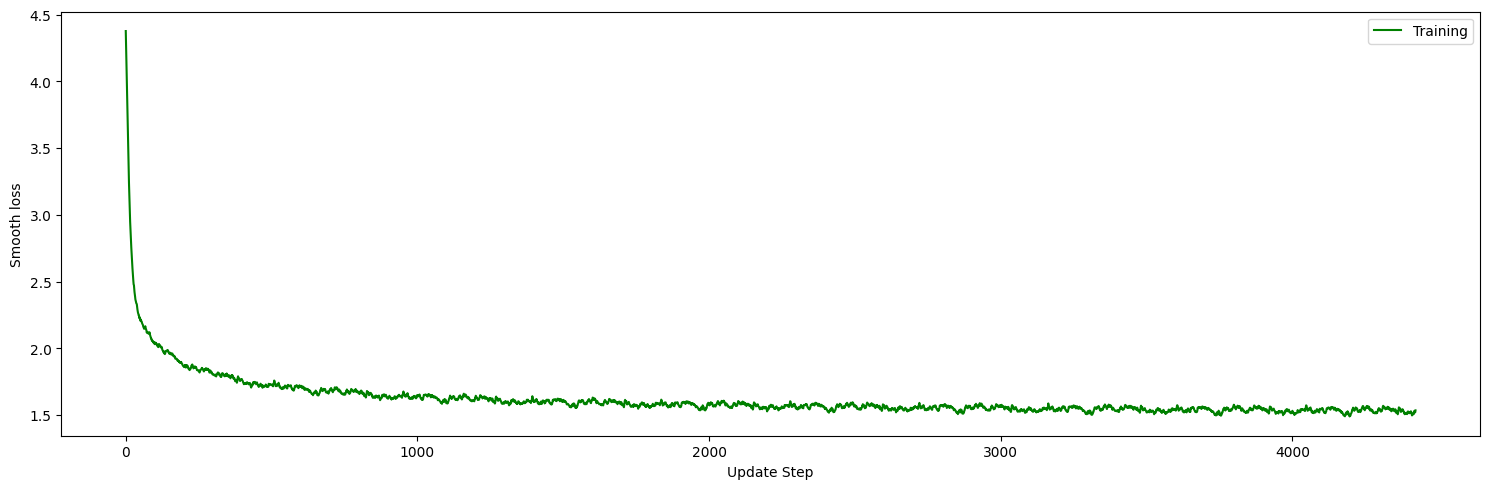

In [15]:
for chunk_size in [1, 2, 4, 8, 16, 32, 64]:
    print(f"Testing chunk size: {chunk_size}")
    net = RecurrentNeuralNetwork(data_handler)
    net.add_layer([
        RecurrentLayer(net, K=data_handler.K, m=100, activation="tanh", lam=0),
        FullyConnectedLayer(net, d=100, m=data_handler.K, activation="softmax", lam=0),
    ])
    net.train_random_order(25, 0.001, 10, chunk_size, f"chunk_exp_model_{chunk_size}.npz")

In [16]:
best_net = RecurrentNeuralNetwork(data_handler)
best_net.add_layer([
    RecurrentLayer(net, K=data_handler.K, m=100, activation="tanh", lam=0),
    FullyConnectedLayer(net, d=100, m=data_handler.K, activation="softmax", lam=0),
])
best_net.load_parameters("chunk_exp_model_64.npz")

Successfully loaded and set model parameters


In [17]:
''.join(best_net.synthesize(1000))

'nk ais and singer of it nobd to hile bed on the bar of wyll his wands, that you comment. . . . . Officking at Hagrid he wasn\'t a conntain and some way as Mr. Weasley take gonation in they gold and Ron larghing very anesed intactaching wing the Magove decidg? stucked,"\nAnd you touch.  Fanciat-Eyt thought him.  Harry dispentions, and said at with yeem slowly from I was clang whicking picky.  Chollowing inteked. Onhink marewat-tipporn, so gold flascitaching scock of sourned one don\'t clut on seen tell the ball handay had giffestonm surpieving at houshed sleak of my - his fewer and claal Threlving it pocked fine ear with the isuch.  It say trenchting in his unlyted, four hand," said I prepped denes, planing then iter are, exament, normired; the Owlent!" Drat!"\nHarry rose this full of nermant of prcubsirafiction," said Hermione pingued at Mrobest, of little to a right hell in his snight hands," said Heasiverus at excrid not out. . . . The dead, the wand.  Mr. Crouch her is at as ow.\no